# 风控异构图构建

## 目标
学习如何在风控场景中构建**异构图（Heterogeneous Graph）**，包含多种节点类型和边类型。

## 为什么需要异构图？
在真实的风控场景中，图的节点不只有一种类型：
- 用户（user）、设备（device）、IP 地址（ip）、手机号（phone）、邮箱（email）...
- 不同的边代表不同的关系：登录、支付、绑定、共用...

同构图 GCN 无法直接处理这种多类型数据，需要使用**异构图神经网络**。

In [1]:
import sys
sys.path.append('..')

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch_geometric.data import HeteroData

from src.data.generate_fraud_data import generate_fraud_dataset, print_dataset_summary
from src.data.graph_builder import build_heterogeneous_graph, train_val_test_split_by_nodes

# 修复 matplotlib 中文显示问题
plt.rcParams['font.sans-serif'] = ['Heiti TC', 'PingFang HK', 'Kaiti SC']
plt.rcParams['axes.unicode_minus'] = False

torch.manual_seed(42)
np.random.seed(42)

print("模块加载成功！")

模块加载成功！


## 1. 生成模拟风控数据

我们使用 `generate_fraud_data.py` 生成包含黑产团伙特征的模拟数据。

数据特征：
- 5000 用户，其中 5% 为欺诈用户，分属 8 个团伙
- 3000 设备、2000 IP、4000 手机号
- 团伙成员**共享设备和 IP**（这是关键的黑产模式）

In [2]:
dataset = generate_fraud_dataset(
    n_users=5000,
    n_devices=3000,
    n_ips=2000,
    n_phones=4000,
    fraud_ratio=0.05,     # 5% 欺诈
    n_gangs=8,             # 8 个团伙
    gang_size_range=(5, 30),
    seed=42,
)

print_dataset_summary(dataset)

风控模拟数据集摘要
  用户总数:          5,000
  欺诈用户:          250 (5.00%)
  欺诈团伙数:        8
  设备数:            3,000
  IP 数:             2,000
  手机号数:          4,000
  用户-设备边:       8,280
  用户-IP 边:        11,249
  用户-手机号边:     8,619
  团伙 0: 12 个成员
  团伙 1: 43 个成员
  团伙 2: 38 个成员
  团伙 3: 27 个成员
  团伙 4: 27 个成员
  团伙 5: 47 个成员
  团伙 6: 12 个成员
  团伙 7: 44 个成员


## 2. 理解模拟数据的结构

看看不同标签用户的特征分布差异。

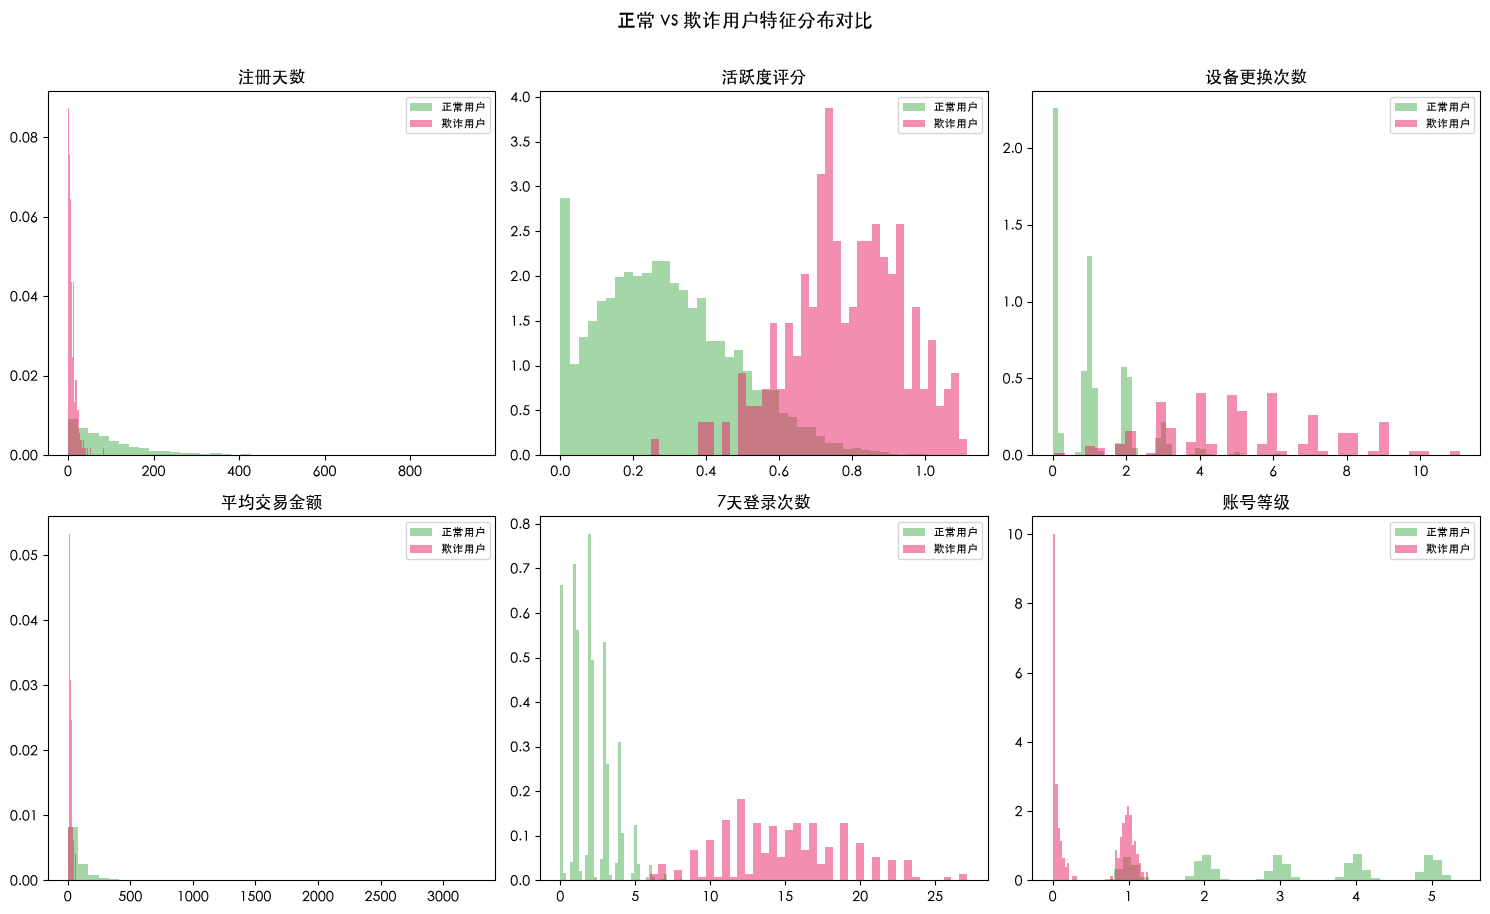

💡 观察: 欺诈用户的特征分布与正常用户有明显差异，但存在重叠。
   仅靠单点特征难以完全区分，需要借助图结构信息。


In [3]:
user_feat = dataset['user_features']
labels = dataset['labels']
feature_names = dataset['feature_names']['user']

# 选取几个关键特征对比
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
compare_indices = [0, 1, 2, 3, 4, 5]  # 对比 6 个特征

for i, idx in enumerate(compare_indices):
    ax = axes[i // 3, i % 3]
    normal_vals = user_feat[labels == 0, idx]
    fraud_vals = user_feat[labels == 1, idx]
    
    ax.hist(normal_vals, bins=40, alpha=0.5, label='正常用户', color='#4CAF50', density=True)
    ax.hist(fraud_vals, bins=40, alpha=0.5, label='欺诈用户', color='#E91E63', density=True)
    ax.set_title(feature_names[idx], fontsize=12)
    ax.legend(fontsize=8)

plt.suptitle('正常 vs 欺诈用户特征分布对比', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

print("💡 观察: 欺诈用户的特征分布与正常用户有明显差异，但存在重叠。")
print("   仅靠单点特征难以完全区分，需要借助图结构信息。")

## 3. 构建异构图的 PyG HeteroData

将模拟数据转换为 PyG 可以处理的 `HeteroData` 格式。

节点类型：`user`, `device`, `ip`, `phone`
边类型：`(user, uses, device)`, `(user, from, ip)`, `(user, has, phone)`

In [4]:
# 划分训练/验证/测试集
n_users = dataset['user_features'].shape[0]
train_mask, val_mask, test_mask = train_val_test_split_by_nodes(
    n_users, train_ratio=0.6, val_ratio=0.2, seed=42
)

print(f"训练集: {train_mask.sum()} | 验证集: {val_mask.sum()} | 测试集: {test_mask.sum()}")

# 构建异构图
data = build_heterogeneous_graph(
    node_features_dict={
        'user': dataset['user_features'],
        'device': dataset['device_features'],
        'ip': dataset['ip_features'],
        'phone': dataset['phone_features'],
    },
    edge_dict={
        ('user', 'uses', 'device'): dataset['user_device_edges'],
        ('user', 'from', 'ip'): dataset['user_ip_edges'],
        ('user', 'has', 'phone'): dataset['user_phone_edges'],
    },
    labels_dict={'user': dataset['labels']},
    train_mask_dict={'user': train_mask},
    val_mask_dict={'user': val_mask},
    test_mask_dict={'user': test_mask},
)

print(f"\n异构图构建完成！")
print(f"  节点类型: {list(data.node_types)}")
print(f"  边类型: {list(data.edge_types)}")
for ntype in data.node_types:
    print(f"  {ntype}: {data[ntype].x.shape[0]:,} 个节点, 特征维度 {data[ntype].x.shape[1]}")

训练集: 3000 | 验证集: 1000 | 测试集: 1000

异构图构建完成！
  节点类型: ['user', 'device', 'ip', 'phone']
  边类型: [('user', 'uses', 'device'), ('user', 'from', 'ip'), ('user', 'has', 'phone')]
  user: 5,000 个节点, 特征维度 8
  device: 3,000 个节点, 特征维度 6
  ip: 2,000 个节点, 特征维度 5
  phone: 4,000 个节点, 特征维度 4


## 4. 分析图结构特征

查看团伙在图结构中的表现——团伙成员的度数（连接数）是否更高？

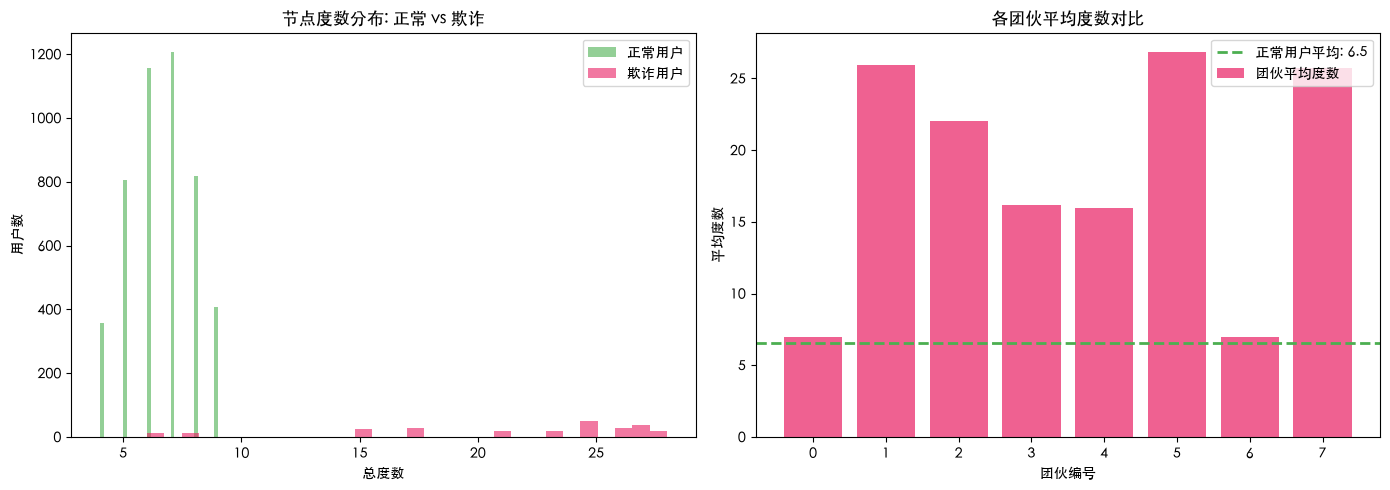

正常用户平均度数: 6.54
欺诈用户平均度数: 21.52

💡 关键洞察: 欺诈用户（团伙成员）的度数显著高于正常用户，
   因为他们共享更多设备和 IP 地址，形成了密集的连接模式。
   这正是 GNN 能够捕获的图结构信号！


In [5]:
# 计算每个用户在 "uses device" 关系上的度数
user_device_edges = data['user', 'uses', 'device'].edge_index
user_degrees_device = torch.bincount(user_device_edges[0], minlength=n_users).numpy()

# 计算每个用户在全部关系上的总度数
total_degrees = user_degrees_device.copy()
for etype in data.edge_types:
    if etype[0] == 'user':
        degree = torch.bincount(data[etype].edge_index[0], minlength=n_users).numpy()
        total_degrees += degree

# 对比正常用户和欺诈用户的度数分布
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(total_degrees[labels == 0], bins=30, alpha=0.6, label='正常用户', color='#4CAF50')
axes[0].hist(total_degrees[labels == 1], bins=30, alpha=0.6, label='欺诈用户', color='#E91E63')
axes[0].set_xlabel('总度数')
axes[0].set_ylabel('用户数')
axes[0].set_title('节点度数分布: 正常 vs 欺诈')
axes[0].legend()

# 团伙度数对比
gang_ids = dataset['gang_ids']
gang_avg_degrees = []
normal_avg_degree = total_degrees[(labels == 0) & (gang_ids == -1)].mean()
for gid in range(8):
    gang_mask = gang_ids == gid
    gang_avg_degrees.append(total_degrees[gang_mask].mean())

axes[1].bar(range(8), gang_avg_degrees, color='#E91E63', alpha=0.7, label='团伙平均度数')
axes[1].axhline(y=normal_avg_degree, color='#4CAF50', linestyle='--', linewidth=2, label=f'正常用户平均: {normal_avg_degree:.1f}')
axes[1].set_xlabel('团伙编号')
axes[1].set_ylabel('平均度数')
axes[1].set_title('各团伙平均度数对比')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"正常用户平均度数: {normal_avg_degree:.2f}")
print(f"欺诈用户平均度数: {total_degrees[labels == 1].mean():.2f}")
print(f"\n💡 关键洞察: 欺诈用户（团伙成员）的度数显著高于正常用户，")
print(f"   因为他们共享更多设备和 IP 地址，形成了密集的连接模式。")
print(f"   这正是 GNN 能够捕获的图结构信号！")

## 5. 可视化团伙子图

用 NetworkX 可视化一个团伙及其关联的设备和 IP。

子图节点数: 58, 边数: 135


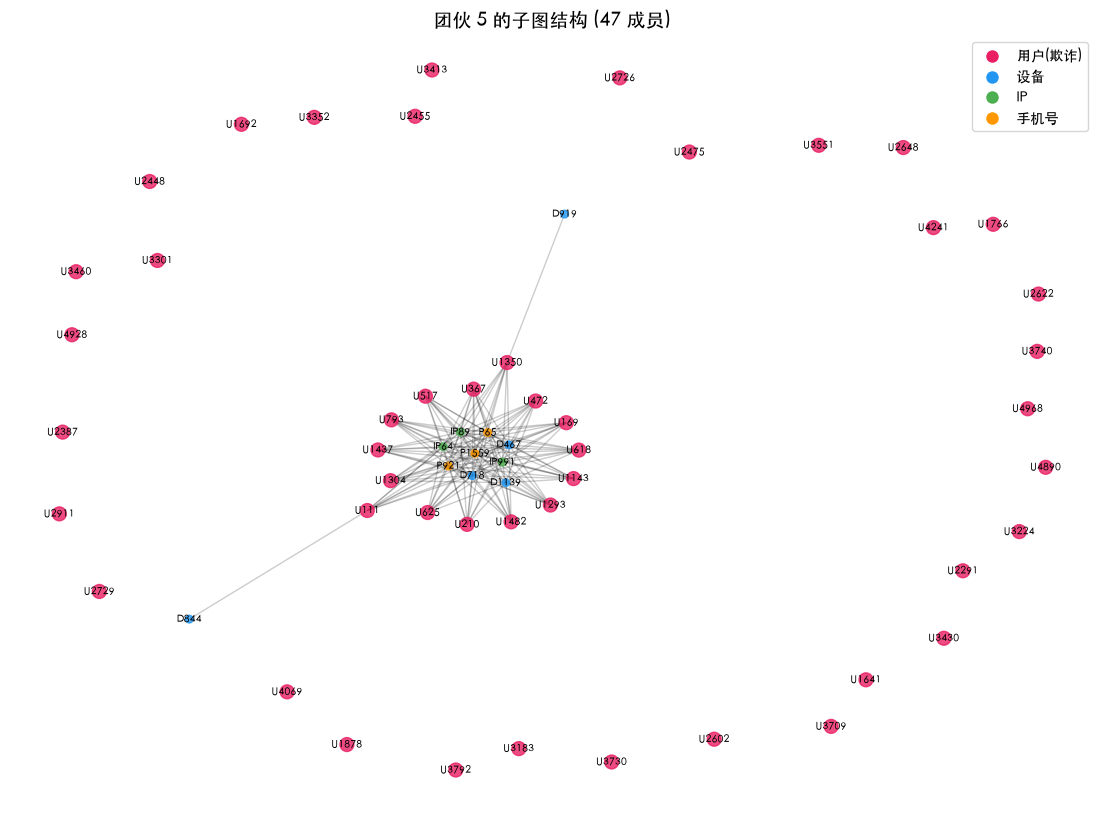


💡 关键洞察: 团伙成员通过少数共享设备和 IP 形成密集子图。
   这种结构模式是 GNN 识别欺诈的核心信号——单看每个用户的行为可能正常，
   但他们之间的异常关联关系暴露了团伙特征。


In [6]:
import networkx as nx

# 选择最大的团伙进行可视化
largest_gang = np.argmax(np.bincount(gang_ids[gang_ids >= 0]))
gang_members = np.where(gang_ids == largest_gang)[0]

# 构建子图：团伙成员 + 他们连接的设备
G = nx.Graph()

# 添加用户节点
for uid in gang_members:
    G.add_node(f"U{uid}", ntype='user', color='#E91E63')

# 添加关联的设备/IP/手机号
for uid in gang_members[:15]:  # 只选前 15 个用户（太多会看不清）
    for etype, node_prefix, color in [
        (('user', 'uses', 'device'), 'D', '#2196F3'),
        (('user', 'from', 'ip'), 'IP', '#4CAF50'),
        (('user', 'has', 'phone'), 'P', '#FF9800'),
    ]:
        edge_index = data[etype].edge_index
        neighbors = edge_index[1][edge_index[0] == uid].numpy()
        for nid in neighbors[:3]:  # 限制每个用户的邻居数
            node_name = f"{node_prefix}{nid}"
            G.add_node(node_name, ntype=etype[2], color=color)
            G.add_edge(f"U{uid}", node_name)

print(f"子图节点数: {len(G.nodes)}, 边数: {len(G.edges)}")

# 可视化
fig, ax = plt.subplots(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)
colors = [G.nodes[n].get('color', '#999') for n in G.nodes]
sizes = [100 if G.nodes[n]['ntype'] == 'user' else 30 for n in G.nodes]

nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=sizes, alpha=0.8, ax=ax)
nx.draw_networkx_edges(G, pos, alpha=0.2, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=7, ax=ax)

# 图例
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#E91E63', markersize=10, label='用户(欺诈)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#2196F3', markersize=10, label='设备'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4CAF50', markersize=10, label='IP'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#FF9800', markersize=10, label='手机号'),
]
ax.legend(handles=legend_elements, loc='upper right')
ax.set_title(f'团伙 {largest_gang} 的子图结构 ({len(gang_members)} 成员)', fontsize=14)
ax.axis('off')
plt.show()

print(f"\n💡 关键洞察: 团伙成员通过少数共享设备和 IP 形成密集子图。")
print(f"   这种结构模式是 GNN 识别欺诈的核心信号——单看每个用户的行为可能正常，")
print(f"   但他们之间的异常关联关系暴露了团伙特征。")

## 关键要点总结

1. **异构图是风控场景的标准建模方式**——多实体 + 多关系
2. **欺诈团伙在图结构上呈现密集连接模式**（共享设备/IP/手机号）
3. **图结构特征（度数、连通性等）本身就包含欺诈信号**
4. 本项目的 `generate_fraud_data.py` 可以生成模拟数据用于学习和实验

> **下一步**：使用这个异构图训练 GNN 模型进行欺诈检测，请参考 `03-欺诈团伙检测实战.ipynb`